In [1]:
import numpy as np

sn = np.load("sn.npy")
print(sn.shape)

(3021, 17122)


/var/folders/yn/cf10_z15625fry9tyf30rq280000gn/T/ipykernel_82687/4192250783.py:39: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow')


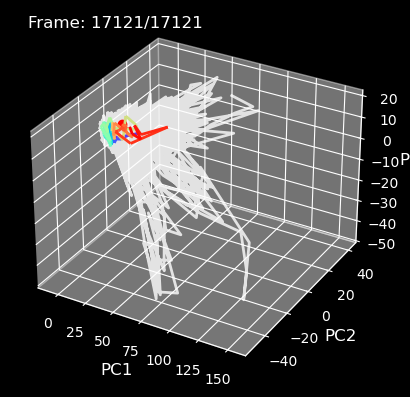

In [2]:
sn_T = sn.T
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from matplotlib import cm
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from mpl_toolkits.mplot3d import Axes3D

plt.style.use('dark_background')

pca = PCA(n_components=3)
sn_pca = pca.fit_transform(sn_T)
# sn_pca = sn_pca[:1000]

from scipy.interpolate import interp1d

t = np.linspace(0, 1, len(sn_pca))

interp_func = interp1d(t, sn_pca, axis=0, kind='linear')
X_smooth = interp_func(t)  

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.set_xlim(np.min(X_smooth[:,0]), np.max(X_smooth[:,0]))
ax.set_ylim(np.min(X_smooth[:,1]), np.max(X_smooth[:,1]))
ax.set_zlim(np.min(X_smooth[:,2]), np.max(X_smooth[:,2]))

ax.set_xlabel("PC1", color='white', fontsize=12)
ax.set_ylabel("PC2", color='white', fontsize=12)
ax.set_zlabel("PC3", color='white', fontsize=12)

frame_text = ax.text2D(0.05, 0.95, "", transform=ax.transAxes, color='white', fontsize=12)

ax.plot(X_smooth[:, 0], X_smooth[:, 1], X_smooth[:, 2],
        color='white', alpha=0.8, lw=2)

# 彩虹 colormap
cmap = cm.get_cmap('rainbow')

# 初始化彩虹轨迹集合（占位避免 add_collection3d 报错）
dummy_segment = np.array([[[0, 0, 0], [0, 0, 0]]])
rainbow_line = Line3DCollection(dummy_segment, colors=[(0, 0, 0, 0)], linewidth=2)
ax.add_collection3d(rainbow_line)

# 红色点
point, = ax.plot([], [], [], 'ro')

# 初始化函数
def init():
    rainbow_line.set_segments(dummy_segment)
    rainbow_line.set_color([(0, 0, 0, 0)])
    point.set_data([], [])
    point.set_3d_properties([])
    frame_text.set_text("")
    return rainbow_line, point, frame_text

# 更新函数（滑动窗口）
tail_len = 80  # 尾迹长度
def update(frame):
    start_idx = max(0, frame - tail_len)
    end_idx = frame

    # 当前尾迹段
    points_tail = X_smooth[start_idx:end_idx].reshape(-1, 1, 3)
    if len(points_tail) > 1:
        segments_tail = np.concatenate([points_tail[:-1], points_tail[1:]], axis=1)
        colors_tail = cmap(np.linspace(0, 1, len(segments_tail)))
    else:
        segments_tail = dummy_segment
        colors_tail = [(0, 0, 0, 0)]

    rainbow_line.set_segments(segments_tail)
    rainbow_line.set_color(colors_tail)

    # 红点位置
    point.set_data(X_smooth[frame, 0:1], X_smooth[frame, 1:2])
    point.set_3d_properties(X_smooth[frame, 2:3])
    
    frame_text.set_text(f"Frame: {frame}/{len(X_smooth)-1}")

    return rainbow_line, point, frame_text

# 创建动画（这里用全局帧数）
ani = FuncAnimation(fig, update, frames=len(X_smooth),
                    init_func=init, blit=True, interval=50)

ani.save('pca_trajectory_rainbow.gif', writer='pillow')
plt.show()

In [ ]:
# Ephys Data Animation
swims1_path = '/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/swims1.npy'
swims2_path = '/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/swims2.npy'

